# Tugas Praktik — AI Cookbook untuk Earth Sciences
## Praktik Recipe dari Buku dan Pembuatan Recipe Mandiri

**Nama:** DITAH ANRIANI  
**NIM:** H061251086 
**Program Studi:** Geofisika  
**Mata kuliah:** AI

### Tujuan
Notebook ini memiliki dua tujuan utama:
1. Mempraktikkan recipe dari buku *AI Cookbook untuk Earth Sciences*, yaitu **R-IO-001: audit station CSV sebelum analisis iklim**.
2. Menyusun dan menjalankan recipe mandiri **R-MET-001** untuk menganalisis kecepatan angin 10 meter (`WS10M`) dari data harian NASA POWER untuk Tokyo pada tahun 2024.

Notebook ini juga mengikuti pola praktik prompt dan recipe: membandingkan prompt, membuat template prompt, memperbaiki prompt secara bertahap, menyusun recipe terstruktur, dan mencatat hasil. Data sumber tidak ditimpa.

## 1. Praktik dari Buku — R-IO-001: Audit QA/QC Data Stasiun Cuaca

### Masalah dan tujuan
Sebelum data cuaca digunakan untuk analisis, perlu dilakukan pemeriksaan awal terhadap struktur kolom, rentang waktu, nilai kosong, timestamp duplikat, dan ringkasan numerik.

### Teori singkat
QA/QC (*Quality Assurance/Quality Control*) adalah proses pemeriksaan kualitas data. Nilai kosong dan timestamp duplikat perlu ditandai agar peneliti dapat meninjau dampaknya. Pemeriksaan ini tidak otomatis menghapus baris atau mengisi nilai kosong; data asli harus tetap dipertahankan.

### Input
Data latihan di bawah ini merupakan *fixture* kecil, bukan observasi cuaca nyata. Data sengaja memuat satu nilai temperatur kosong dan satu timestamp duplikat untuk memastikan pemeriksaan dapat mendeteksi keduanya.

In [1]:
import pandas as pd
from io import StringIO
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

csv_contoh = StringIO(
    "time,temperature,humidity,wind_speed\n"
    "2026-01-01,28.5,80,3.2\n"
    "2026-01-02,,82,2.8\n"
    "2026-01-03,29.1,78,4.1\n"
    "2026-01-03,29.1,78,4.1\n"
    "2026-01-04,30.0,75,3.6\n"
)
data_audit = pd.read_csv(csv_contoh)
data_audit["time"] = pd.to_datetime(data_audit["time"], errors="coerce")

print("Ukuran data:", data_audit.shape)
print("\nTipe data:")
print(data_audit.dtypes)
print("\nRentang waktu:", data_audit["time"].min(), "sampai", data_audit["time"].max())
print("\nNilai kosong per kolom:")
print(data_audit.isna().sum())
print("\nJumlah timestamp duplikat:", int(data_audit["time"].duplicated(keep=False).sum()))
print("\nRingkasan numerik:")
display(data_audit.select_dtypes(include=[np.number]).describe())

Ukuran data: (5, 4)

Tipe data:
time           datetime64[us]
temperature           float64
humidity                int64
wind_speed            float64
dtype: object

Rentang waktu: 2026-01-01 00:00:00 sampai 2026-01-04 00:00:00

Nilai kosong per kolom:
time           0
temperature    1
humidity       0
wind_speed     0
dtype: int64

Jumlah timestamp duplikat: 2

Ringkasan numerik:


,temperature,humidity,wind_speed
count,4.000000,5.000000,5.000000
mean,29.175000,78.600000,3.560000
std,0.618466,2.607681,0.568331
min,28.500000,75.000000,2.800000
25%,28.950000,78.000000,3.200000
50%,29.100000,78.000000,3.600000
75%,29.325000,80.000000,4.100000
max,30.000000,82.000000,4.100000


### Prompt yang digunakan untuk praktik recipe buku

In [2]:
prompt_audit = """
Periksa data stasiun cuaca secara read-only.
Laporkan struktur kolom dan tipe data, rentang waktu,
jumlah nilai kosong per kolom, timestamp duplikat,
serta ringkasan statistik numerik.
Jangan menghapus baris, mengisi nilai kosong, atau menimpa data sumber.
Simpan hasil sebagai laporan Markdown dan tampilkan pemeriksaan yang dapat diverifikasi.
"""
print(prompt_audit)


Periksa data stasiun cuaca secara read-only.
Laporkan struktur kolom dan tipe data, rentang waktu,
jumlah nilai kosong per kolom, timestamp duplikat,
serta ringkasan statistik numerik.
Jangan menghapus baris, mengisi nilai kosong, atau menimpa data sumber.
Simpan hasil sebagai laporan Markdown dan tampilkan pemeriksaan yang dapat diverifikasi.



### Output dan pemeriksaan
Pemeriksaan berikut membandingkan hasil dengan kondisi fixture yang memang sengaja dibuat: lima baris, empat kolom, satu nilai temperatur kosong, dan satu tanggal duplikat (dua baris memiliki timestamp yang sama). Untuk hitungan timestamp, `duplicated(keep=False)` menandai kedua baris yang terlibat dalam duplikasi.

In [3]:
missing_temperature = int(data_audit["temperature"].isna().sum())
duplicate_rows = int(data_audit["time"].duplicated(keep=False).sum())

checks_audit = {
    "Data contoh berisi 5 baris dan 4 kolom": data_audit.shape == (5, 4),
    "Terdapat tepat 1 temperatur kosong": missing_temperature == 1,
    "Terdapat 2 baris yang terlibat dalam timestamp duplikat": duplicate_rows == 2,
    "Kolom waktu berhasil diparsing menjadi datetime": pd.api.types.is_datetime64_any_dtype(data_audit["time"])
}
for nama, hasil in checks_audit.items():
    print(("PASS" if hasil else "FAIL") + " — " + nama)
assert all(checks_audit.values()), "Audit fixture tidak sesuai kondisi yang diharapkan."

PASS — Data contoh berisi 5 baris dan 4 kolom
PASS — Terdapat tepat 1 temperatur kosong
PASS — Terdapat 2 baris yang terlibat dalam timestamp duplikat
PASS — Kolom waktu berhasil diparsing menjadi datetime


### Menulis laporan audit
Laporan disusun sebagai teks Markdown tanpa membutuhkan paket tambahan seperti `tabulate`. File akan dibuat di folder kerja notebook.

In [4]:
laporan_audit = f"""# Laporan Audit QA/QC Data Stasiun

## Ringkasan
- Jumlah baris: {len(data_audit)}
- Jumlah kolom: {len(data_audit.columns)}
- Rentang waktu: {data_audit['time'].min().date()} sampai {data_audit['time'].max().date()}
- Jumlah nilai temperatur kosong: {missing_temperature}
- Jumlah baris yang terlibat dalam timestamp duplikat: {duplicate_rows}

## Kolom
{chr(10).join('- ' + str(c) + ': ' + str(data_audit[c].dtype) for c in data_audit.columns)}

## Nilai kosong per kolom
{chr(10).join('- ' + str(k) + ': ' + str(v) for k, v in data_audit.isna().sum().items())}

## Catatan
Data sumber tidak dihapus, tidak diimputasi, dan tidak ditimpa. Temuan harus ditinjau sebelum analisis lanjutan.
"""

Path("station-summary.md").write_text(laporan_audit, encoding="utf-8")
print(laporan_audit)
print("\nLaporan tersimpan di:", Path("station-summary.md").resolve())

# Laporan Audit QA/QC Data Stasiun

## Ringkasan
- Jumlah baris: 5
- Jumlah kolom: 4
- Rentang waktu: 2026-01-01 sampai 2026-01-04
- Jumlah nilai temperatur kosong: 1
- Jumlah baris yang terlibat dalam timestamp duplikat: 2

## Kolom
- time: datetime64[us]
- temperature: float64
- humidity: int64
- wind_speed: float64

## Nilai kosong per kolom
- time: 0
- temperature: 1
- humidity: 0
- wind_speed: 0

## Catatan
Data sumber tidak dihapus, tidak diimputasi, dan tidak ditimpa. Temuan harus ditinjau sebelum analisis lanjutan.


Laporan tersimpan di: C:\Users\ThinkPad X13\Downloads\station-summary.md


## 2. Praktik Prompt — Membandingkan Prompt Lemah dan Prompt yang Lebih Baik

Prompt yang terlalu umum sering menghasilkan jawaban yang sulit diverifikasi. Prompt yang baik menyebutkan konteks, input, batasan, output, dan kriteria pemeriksaan.

In [16]:
prompt_lemah = "Analisis data angin Tokyo."
prompt_baik = """
Bertindak sebagai asisten analisis data meteorologi.
Gunakan data harian NASA POWER Tokyo tahun 2024 dengan kolom WS10M.
Periksa format tanggal, jumlah data, nilai kosong, dan tanggal duplikat.
Hitung rata-rata, median, minimum, maksimum, dan simpangan baku WS10M.
Buat grafik deret waktu dan histogram dengan label serta satuan yang jelas.
Jangan mengubah file sumber. Nyatakan keterbatasan analisis dan tampilkan pemeriksaan otomatis.
"""

print("PROMPT LEMAH:\n", prompt_lemah)
print("\nPROMPT YANG DIPERBAIKI:\n", prompt_baik)

PROMPT LEMAH:
 Analisis data angin Tokyo.

PROMPT YANG DIPERBAIKI:
 
Bertindak sebagai asisten analisis data meteorologi.
Gunakan data harian NASA POWER Tokyo tahun 2024 dengan kolom WS10M.
Periksa format tanggal, jumlah data, nilai kosong, dan tanggal duplikat.
Hitung rata-rata, median, minimum, maksimum, dan simpangan baku WS10M.
Buat grafik deret waktu dan histogram dengan label serta satuan yang jelas.
Jangan mengubah file sumber. Nyatakan keterbatasan analisis dan tampilkan pemeriksaan otomatis.



### Pemeriksaan prompt
Prompt yang lebih baik secara eksplisit menyatakan data, parameter, pekerjaan yang diminta, batasan terhadap data sumber, visualisasi, dan pemeriksaan hasil.

In [18]:
kriteria_prompt = {
    "Menyebutkan sumber dan lokasi data": "NASA POWER Tokyo" in prompt_baik,
    "Menyebutkan parameter": "WS10M" in prompt_baik,
    "Meminta pemeriksaan kualitas data": "tanggal duplikat" in prompt_baik,
    "Meminta statistik dan visualisasi": "histogram" in prompt_baik,
    "Melarang perubahan data sumber": "Jangan mengubah file sumber" in prompt_baik,
    "Meminta keterbatasan dan checks": "keterbatasan" in prompt_baik and "pemeriksaan otomatis" in prompt_baik
}
for nama, hasil in kriteria_prompt.items():
    print(("PASS" if hasil else "FAIL") + " — " + nama)
assert all(kriteria_prompt.values())

PASS — Menyebutkan sumber dan lokasi data
PASS — Menyebutkan parameter
PASS — Meminta pemeriksaan kualitas data
PASS — Meminta statistik dan visualisasi
PASS — Melarang perubahan data sumber
PASS — Meminta keterbatasan dan checks


## 3. Praktik Prompt Template dan Iterative Prompt Refinement

Template prompt membuat instruksi dapat digunakan kembali untuk data lain. *Iterative prompt refinement* berarti memperbaiki prompt berdasarkan kekurangan yang ditemukan, dengan batas perubahan yang jelas.

In [7]:
template_prompt = {
    "tujuan": "[tujuan analisis]",
    "sumber_data": "[nama sumber dan lokasi]",
    "periode": "[tanggal mulai dan akhir]",
    "parameter": "[nama kolom dan satuan]",
    "pemeriksaan": "[missing value, duplikasi, format]",
    "analisis": "[statistik atau metode]",
    "visualisasi": "[jenis grafik dan label]",
    "batasan": "Jangan mengubah data sumber; jangan mengarang nilai yang tidak tersedia.",
    "output": "[tabel, grafik, laporan]",
    "kriteria_lulus": "[checks yang dapat diverifikasi]"
}
display(pd.DataFrame({"Bagian": list(template_prompt.keys()), "Isi template": list(template_prompt.values())}))

,Bagian,Isi template
0,tujuan,[tujuan analisis]
1,sumber_data,[nama sumber dan lokasi]
2,periode,[tanggal mulai dan akhir]
3,parameter,[nama kolom dan satuan]
4,pemeriksaan,"[missing value, duplikasi, format]"
5,analisis,[statistik atau metode]
6,visualisasi,[jenis grafik dan label]
7,batasan,Jangan mengubah data sumber; jangan mengarang ...
8,output,"[tabel, grafik, laporan]"
9,kriteria_lulus,[checks yang dapat diverifikasi]


In [8]:
# Iterasi 1: prompt awal terlalu umum.
prompt_awal = "Hitung statistik angin Tokyo."

# Iterasi 2: menambahkan sumber data, parameter, dan periode.
prompt_iterasi_2 = (
    "Gunakan data harian NASA POWER Tokyo tahun 2024. "
    "Analisis parameter WS10M."
)

# Iterasi 3: menambahkan QA/QC, output, batasan, dan kriteria verifikasi.
prompt_final = (
    "Gunakan data harian NASA POWER Tokyo tahun 2024 dan parameter WS10M. "
    "Periksa jumlah baris, tanggal tidak valid, nilai kosong, dan tanggal duplikat. "
    "Hitung statistik deskriptif serta buat grafik deret waktu dan histogram. "
    "Jangan mengubah data sumber. Tampilkan checks PASS/FAIL dan simpulkan hasil "
    "dengan menyebutkan keterbatasan."
)

for judul, isi in [
    ("Prompt awal", prompt_awal),
    ("Iterasi 2", prompt_iterasi_2),
    ("Prompt final", prompt_final)
]:
    print(f"--- {judul} ---\n{isi}\n")

--- Prompt awal ---
Hitung statistik angin Tokyo.

--- Iterasi 2 ---
Gunakan data harian NASA POWER Tokyo tahun 2024. Analisis parameter WS10M.

--- Prompt final ---
Gunakan data harian NASA POWER Tokyo tahun 2024 dan parameter WS10M. Periksa jumlah baris, tanggal tidak valid, nilai kosong, dan tanggal duplikat. Hitung statistik deskriptif serta buat grafik deret waktu dan histogram. Jangan mengubah data sumber. Tampilkan checks PASS/FAIL dan simpulkan hasil dengan menyebutkan keterbatasan.



### Apa yang diperbaiki?
- Prompt awal hanya menyebut pekerjaan secara umum.
- Iterasi kedua menetapkan sumber data, lokasi, periode, dan parameter.
- Prompt final menambahkan pemeriksaan kualitas, statistik, grafik, larangan mengubah data sumber, serta output yang dapat diverifikasi.

## 4. Praktik Mengubah Task Menjadi Recipe Terstruktur

### Recipe dari buku
- **Recipe ID:** R-IO-001
- **Problem:** memeriksa kualitas awal data stasiun cuaca.
- **Minimal theory:** nilai kosong dan timestamp duplikat dapat memengaruhi analisis.
- **Input:** tabel stasiun cuaca dengan kolom waktu dan variabel meteorologi.
- **Constraints:** read-only; tidak menghapus atau mengimputasi data.
- **Implementation:** periksa schema, rentang waktu, nilai kosong, duplikasi, dan statistik numerik.
- **Output:** laporan Markdown.
- **Checks:** struktur dan temuan sesuai data yang diuji.

### Recipe mandiri
- **Recipe ID:** R-MET-001
- **Problem:** memahami karakteristik kecepatan angin 10 meter harian di Tokyo selama 2024.
- **Minimal theory:** statistik deskriptif merangkum sebaran data; deret waktu menunjukkan perubahan dari hari ke hari.
- **Input:** data harian NASA POWER, kolom `YEAR`, `MO`, `DY`, dan `WS10M`.
- **Constraints:** tidak mengubah file sumber; satuan mengikuti metadata sumber dan tidak ditebak bila tidak tersedia.
- **Implementation:** parsing tanggal, QA/QC, statistik, grafik, dan checks.
- **Output:** ringkasan statistik dan dua grafik.
- **Checks:** tanggal valid, nilai WS10M valid, dan data memiliki baris.

## 5. Praktik Catatan Tugas dengan Markdown

Markdown digunakan untuk menyimpan ringkasan tugas yang mudah dibaca dan dapat dibuka sebagai berkas teks. Contoh di bawah membuat catatan singkat untuk recipe mandiri.

In [19]:
catatan_tugas_md = """# Catatan Recipe R-MET-001

## Tujuan
Menganalisis kecepatan angin 10 meter (`WS10M`) harian di Tokyo selama 2024.

## Langkah
1. Membaca data NASA POWER.
2. Membentuk tanggal dari YEAR, MO, dan DY.
3. Memeriksa tanggal duplikat dan nilai kosong.
4. Menghitung statistik deskriptif.
5. Membuat grafik deret waktu dan histogram.
6. Memeriksa hasil sebelum menarik kesimpulan.

## Batasan
Analisis ini bersifat deskriptif. Hasil tidak dengan sendirinya menjelaskan penyebab meteorologis perubahan kecepatan angin.
"""
Path("catatan-R-MET-001.md").write_text(catatan_tugas_md, encoding="utf-8")
print(catatan_tugas_md)
print("\nCatatan tersimpan di:", Path("catatan-R-MET-001.md").resolve())

# Catatan Recipe R-MET-001

## Tujuan
Menganalisis kecepatan angin 10 meter (`WS10M`) harian di Tokyo selama 2024.

## Langkah
1. Membaca data NASA POWER.
2. Membentuk tanggal dari YEAR, MO, dan DY.
3. Memeriksa tanggal duplikat dan nilai kosong.
4. Menghitung statistik deskriptif.
5. Membuat grafik deret waktu dan histogram.
6. Memeriksa hasil sebelum menarik kesimpulan.

## Batasan
Analisis ini bersifat deskriptif. Hasil tidak dengan sendirinya menjelaskan penyebab meteorologis perubahan kecepatan angin.


Catatan tersimpan di: C:\Users\ThinkPad X13\Downloads\catatan-R-MET-001.md


## 6. Recipe Mandiri — Analisis WS10M NASA POWER Tokyo

### Input data
Data `Data daily Tokyo.txt` yang digunakan dalam notebook ini merupakan data yang telah diberikan untuk tugas. Isinya ditanamkan langsung ke notebook sehingga tidak diperlukan path file eksternal untuk menjalankan analisis ini.

In [10]:
from io import StringIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data_teks = 'YEAR  MO  DY  ALLSKY_SFC_SW_DWN   T2M  RH2M  WS10M     PS\n2024   1   1               3.32  7.86 70.86   6.24 101.44\n2024   1   2               1.41  6.63 88.32   2.21 101.62\n2024   1   3               1.75  6.55 83.88   1.92 100.94\n2024   1   4               3.18  8.08 78.77   5.45 100.84\n2024   1   5               3.21  7.14 78.03   2.98 101.50\n2024   1   6               3.14  9.44 76.12   3.98 100.93\n2024   1   7               2.76  7.52 68.13   4.36 100.49\n2024   1   8               3.40  4.01 66.42   4.83 101.39\n2024   1   9               3.28  4.95 72.29   3.41 101.34\n2024   1  10               2.33  6.58 73.07   3.91 100.85\n2024   1  11               1.48  4.31 77.36   5.76 100.87\n2024   1  12               3.36  6.76 70.66   3.35 100.58\n2024   1  13               2.79  4.93 76.33   3.98 100.79\n2024   1  14               3.50  5.15 66.42   4.67 101.62\n2024   1  15               3.37  6.25 67.26   6.59 100.81\n2024   1  16               3.46  2.06 63.70   6.68 101.65\n2024   1  17               3.59  5.90 67.75   2.37 102.19\n2024   1  18               2.91  8.39 76.38   2.26 101.59\n2024   1  19               2.93  8.26 76.88   5.09 101.93\n2024   1  20               1.24  6.71 84.22   4.73 102.29\n2024   1  21               1.00  9.49 93.34   4.52 100.81\n2024   1  22               2.22  9.61 85.52   3.90 101.01\n2024   1  23               2.89  7.98 73.50   3.62 100.10\n2024   1  24               3.18  3.69 59.89   6.16 100.11\n2024   1  25               3.91  3.15 59.34   6.01 100.74\n2024   1  26               3.93  3.81 65.28   5.56 101.13\n2024   1  27               3.63  4.69 69.35   4.63 101.49\n2024   1  28               2.33  4.97 74.60   3.15 101.65\n2024   1  29               3.93  5.61 67.59   3.25 102.27\n2024   1  30               3.79  7.55 66.61   2.41 102.39\n2024   1  31               3.66  8.92 81.05   3.57 101.94\n2024   2   1               2.97  9.33 72.37   6.26 101.12\n2024   2   2               1.85  3.96 65.79   4.51 101.83\n2024   2   3               3.98  4.94 65.53   3.48 102.14\n2024   2   4               1.43  4.50 81.14   3.64 101.98\n2024   2   5               0.82  2.90 90.21   5.81 101.40\n2024   2   6               1.83  2.86 91.12   6.30 101.13\n2024   2   7               3.49  4.08 72.07   2.95 101.17\n2024   2   8               3.57  4.65 78.10   3.54 101.17\n2024   2   9               3.81  5.48 76.36   4.08 101.35\n2024   2  10               3.88  6.13 77.57   2.90 101.16\n2024   2  11               3.51  6.66 66.53   3.27 101.37\n2024   2  12               4.42  5.18 74.91   4.25 101.95\n2024   2  13               4.65  8.68 73.02   5.19 102.36\n2024   2  14               4.50 10.37 74.26   2.72 102.00\n2024   2  15               3.28 13.59 83.78   6.92 101.22\n2024   2  16               4.40  9.01 65.52   7.40 101.17\n2024   2  17               2.53  7.88 77.76   3.60 102.03\n2024   2  18               3.16 11.95 78.07   2.60 102.40\n2024   2  19               1.55 14.92 79.84   7.46 101.86\n2024   2  20               3.47 17.00 79.25   6.27 101.31\n2024   2  21               0.51  9.50 83.70   5.16 101.54\n2024   2  22               1.10  4.96 86.18   6.86 101.50\n2024   2  23               1.49  3.02 89.43   6.08 101.77\n2024   2  24               4.56  4.50 72.51   4.44 102.15\n2024   2  25               1.15  5.96 88.73   4.24 101.56\n2024   2  26               4.85  6.64 71.98   8.40 100.91\n2024   2  27               5.34  5.35 65.72   8.77 101.24\n2024   2  28               5.23  6.18 66.45   5.84 101.98\n2024   2  29               3.44  7.02 75.80   2.73 101.90\n2024   3   1               4.06  9.34 78.17   4.96  99.94\n2024   3   2               4.17  5.05 62.52   5.47 100.81\n2024   3   3               5.40  5.90 63.15   3.89 101.11\n2024   3   4               5.02  7.76 65.79   4.26 101.37\n2024   3   5               1.72  6.28 81.03   3.95 101.52\n2024   3   6               1.86  6.24 91.56   7.67 100.22\n2024   3   7               3.44  6.24 72.52   4.94 100.93\n2024   3   8               3.57  5.05 87.12   3.67 100.30\n2024   3   9               5.62  5.06 65.75   5.90 100.68\n2024   3  10               5.80  5.20 68.31   4.48 101.88\n2024   3  11               5.66  6.88 71.01   3.51 102.03\n2024   3  12               1.56 10.18 89.27   5.40 100.29\n2024   3  13               5.85  7.72 68.16   6.64 100.57\n2024   3  14               5.75  7.78 68.19   3.16 101.33\n2024   3  15               5.90  9.54 68.69   3.84 101.38\n2024   3  16               5.69 11.34 67.41   4.06 101.50\n2024   3  17               4.64 14.60 81.61   6.75 100.60\n2024   3  18               6.25  7.23 59.10   9.03 100.77\n2024   3  19               4.26  6.67 65.67   3.76 101.21\n2024   3  20               4.36  8.89 69.03   7.97  99.62\n2024   3  21               6.28  5.02 60.11   7.44 100.63\n2024   3  22               6.55  5.66 61.17   4.13 101.54\n2024   3  23               2.39  6.16 86.26   2.06 101.47\n2024   3  24               2.22  9.20 90.22   1.94 101.56\n2024   3  25               1.60 11.88 90.75   3.49 101.04\n2024   3  26               0.92 10.28 93.70   6.11 100.28\n2024   3  27               6.42  8.99 69.13   4.62 101.57\n2024   3  28               2.49 10.78 76.06   4.15 101.87\n2024   3  29               2.78 15.64 88.99   9.09 100.39\n2024   3  30               6.54 16.46 77.93   3.66 100.52\n2024   3  31               6.24 18.02 80.06   5.42 100.36\n2024   4   1               3.90 13.83 78.86   3.13 100.35\n2024   4   2               5.54 12.08 67.47   3.66 101.30\n2024   4   3               1.25 13.91 90.49   2.93 100.82\n2024   4   4               3.03 15.31 84.60   2.98 100.31\n2024   4   5               1.18 10.93 82.48   4.18 101.51\n2024   4   6               3.33 12.71 90.47   2.67 101.61\n2024   4   7               4.78 16.19 87.00   2.06 101.36\n2024   4   8               3.23 17.15 91.20   2.58 101.32\n2024   4   9               1.32 15.38 85.29   8.81 100.51\n2024   4  10               7.26 10.00 69.05   4.76 102.23\n2024   4  11               5.53 13.11 74.85   2.50 102.38\n2024   4  12               3.69 14.39 85.88   3.60 101.57\n2024   4  13               6.23 15.19 84.31   4.37 101.35\n2024   4  14               6.75 16.40 81.13   2.22 101.75\n2024   4  15               6.35 17.13 79.07   3.15 101.72\n2024   4  16               6.00 16.73 82.21   5.97 101.26\n2024   4  17               5.50 18.60 82.27   3.63 100.49\n2024   4  18               2.45 16.21 84.78   4.18 100.14\n2024   4  19               6.99 15.52 70.91   6.75 100.09\n2024   4  20               5.55 17.04 67.22   2.66 100.78\n2024   4  21               3.77 17.81 81.50   2.63 100.93\n2024   4  22               2.00 16.82 89.85   3.84 100.82\n2024   4  23               2.20 16.60 82.22   3.68 101.18\n2024   4  24               1.83 15.48 87.56   4.29 100.86\n2024   4  25               6.61 18.77 78.63   2.84 100.15\n2024   4  26               4.97 18.57 80.29   2.82 100.93\n2024   4  27               2.60 18.60 87.18   2.53 100.81\n2024   4  28               7.02 19.82 80.26   2.73 100.96\n2024   4  29               4.80 19.64 85.71   4.11 100.82\n2024   4  30               3.42 20.26 86.00   2.99  99.92\n2024   5   1               1.50 16.30 88.26   5.81 100.14\n2024   5   2               5.96 14.52 76.52   5.40 101.17\n2024   5   3               7.67 16.74 73.50   2.80 101.44\n2024   5   4               7.73 19.60 74.07   2.50 101.54\n2024   5   5               7.89 19.58 78.53   5.17 101.76\n2024   5   6               2.90 19.57 83.21   7.15 101.46\n2024   5   7               1.99 19.82 89.51   7.35 100.50\n2024   5   8               4.73 18.32 82.12   3.96 100.23\n2024   5   9               4.41 12.75 76.58   4.54 100.92\n2024   5  10               7.87 15.73 70.94   3.92 101.69\n2024   5  11               8.09 18.40 78.15   6.41 101.82\n2024   5  12               3.59 19.54 80.63   6.14 101.38\n2024   5  13               1.59 19.70 91.81   7.49 100.50\n2024   5  14               6.58 15.88 78.02   4.61 101.26\n2024   5  15               6.80 17.50 79.81   2.73 101.09\n2024   5  16               4.72 18.55 82.20   6.32 100.17\n2024   5  17               7.75 18.89 70.25   3.93 100.93\n2024   5  18               7.87 20.36 76.51   2.89 101.42\n2024   5  19               2.65 19.47 84.00   1.91 101.43\n2024   5  20               3.58 18.74 84.65   2.35 100.90\n2024   5  21               5.82 21.27 76.01   2.06 101.07\n2024   5  22               5.68 19.56 73.44   3.62 101.50\n2024   5  23               4.02 20.12 85.58   4.09 100.88\n2024   5  24               5.76 22.14 78.01   2.46 100.22\n2024   5  25               5.24 19.43 70.16   3.94 100.88\n2024   5  26               5.41 20.29 77.68   4.07 101.19\n2024   5  27               2.10 21.83 90.23   7.01 100.26\n2024   5  28               2.45 23.78 90.42   9.17  99.76\n2024   5  29               6.29 21.43 76.73   4.22 100.24\n2024   5  30               6.20 21.60 78.84   2.61 101.04\n2024   5  31               2.70 19.53 88.20   3.81 100.36\n2024   6   1               6.49 20.23 80.40   2.62 100.41\n2024   6   2               3.76 20.01 83.15   3.85 100.32\n2024   6   3               5.43 19.87 81.01   2.47 100.18\n2024   6   4               7.11 19.32 77.75   3.19 100.64\n2024   6   5               7.96 19.72 75.09   3.06 101.27\n2024   6   6               5.12 20.54 77.71   2.98 101.53\n2024   6   7               5.68 20.71 76.64   3.03 101.33\n2024   6   8               7.59 21.28 76.96   2.62 101.20\n2024   6   9               4.19 21.39 80.25   3.45 100.92\n2024   6  10               3.81 20.87 80.30   2.98 100.53\n2024   6  11               7.52 22.74 79.24   3.04 100.53\n2024   6  12               7.59 23.12 81.88   3.40 100.45\n2024   6  13               2.56 21.88 85.54   1.63 100.09\n2024   6  14               7.68 24.27 78.74   2.93 100.38\n2024   6  15               6.41 22.71 80.52   2.65 100.40\n2024   6  16               5.63 23.79 85.60   3.90  99.89\n2024   6  17               4.02 25.19 80.14   2.25 100.37\n2024   6  18               0.65 20.84 92.11   2.66 100.20\n2024   6  19               8.10 22.73 73.49   2.80 100.46\n2024   6  20               5.19 22.89 80.89   4.38 100.66\n2024   6  21               1.29 20.62 90.94   5.44 100.15\n2024   6  22               6.20 22.84 78.88   3.90 100.37\n2024   6  23               1.85 24.21 93.27   6.82  99.63\n2024   6  24               6.15 27.30 81.79   3.50  99.70\n2024   6  25               4.78 26.10 83.50   3.75 100.24\n2024   6  26               5.67 25.94 79.56   1.47 100.70\n2024   6  27               5.18 24.44 81.51   3.03 101.00\n2024   6  28               1.35 23.34 92.60   5.23 100.59\n2024   6  29               4.81 24.35 85.44   2.48 100.54\n2024   6  30               3.24 25.00 88.43   6.31 100.43\n2024   7   1               1.88 26.07 91.42   8.61  99.83\n2024   7   2               5.22 26.36 81.99   2.37 100.42\n2024   7   3               5.73 27.17 82.02   2.51 100.71\n2024   7   4               6.55 28.95 82.32   2.00 100.16\n2024   7   5               7.37 29.10 79.35   2.40 100.11\n2024   7   6               5.38 28.64 82.68   2.14 100.28\n2024   7   7               6.77 28.91 85.21   2.57 100.21\n2024   7   8               6.06 30.28 78.46   1.59 100.03\n2024   7   9               3.50 28.52 83.01   4.61 100.03\n2024   7  10               4.27 28.31 82.34   4.74 100.06\n2024   7  11               2.08 26.80 90.12   7.47  99.62\n2024   7  12               1.89 25.70 91.74   3.19  99.78\n2024   7  13               5.26 25.34 77.22   3.21 100.47\n2024   7  14               3.15 26.52 87.24   3.18 100.90\n2024   7  15               3.91 26.71 89.94   2.83 100.99\n2024   7  16               2.43 26.00 88.00   2.20 101.07\n2024   7  17               4.92 26.06 88.87   1.43 100.74\n2024   7  18               5.80 28.41 79.61   2.15 100.68\n2024   7  19               5.68 28.10 85.72   4.87 100.53\n2024   7  20               6.05 29.28 84.80   3.22 100.48\n2024   7  21               6.78 28.83 82.32   2.88 100.57\n2024   7  22               6.65 30.45 77.98   2.28 100.41\n2024   7  23               7.24 29.04 83.61   2.85 100.33\n2024   7  24               5.52 29.33 82.69   2.92 100.12\n2024   7  25               6.18 28.17 84.23   2.52 100.43\n2024   7  26               5.89 28.63 85.76   2.66 100.97\n2024   7  27               5.76 30.26 75.82   1.21 101.24\n2024   7  28               6.02 30.41 75.57   2.16 100.74\n2024   7  29               6.31 30.40 73.97   2.65 100.06\n2024   7  30               4.30 29.93 74.37   2.24  99.68\n2024   7  31               5.38 29.06 79.99   2.21  99.86\n2024   8   1               6.37 27.79 80.53   3.22 100.13\n2024   8   2               6.53 27.81 78.49   2.52 100.21\n2024   8   3               6.56 28.09 75.46   2.05 100.38\n2024   8   4               6.74 28.73 75.57   1.98 100.36\n2024   8   5               5.45 28.90 77.01   1.84 100.26\n2024   8   6               4.85 28.98 78.27   1.86 100.18\n2024   8   7               5.31 28.51 84.12   1.95  99.99\n2024   8   8               5.44 28.96 79.41   1.73  99.89\n2024   8   9               6.13 28.94 80.51   3.30  99.72\n2024   8  10               6.05 28.81 79.69   4.04  99.57\n2024   8  11               6.34 29.97 77.76   2.95  99.50\n2024   8  12               6.40 29.54 82.61   4.36  99.73\n2024   8  13               6.30 29.78 80.38   3.98 100.22\n2024   8  14               5.37 29.70 78.94   3.21 100.31\n2024   8  15               5.83 28.96 81.01   2.90 100.22\n2024   8  16               1.62 27.33 91.32   9.47  99.61\n2024   8  17               5.90 29.57 77.70   4.09 100.05\n2024   8  18               5.05 29.06 84.81   2.28 100.48\n2024   8  19               5.24 29.30 86.53   2.67 100.69\n2024   8  20               5.51 28.90 82.66   2.49 100.84\n2024   8  21               5.45 28.25 82.58   2.81 100.81\n2024   8  22               3.66 27.49 86.56   4.03 100.79\n2024   8  23               4.96 28.02 84.51   5.12 100.78\n2024   8  24               5.39 28.41 81.68   5.04 100.74\n2024   8  25               5.50 28.27 82.83   4.79 100.69\n2024   8  26               5.99 27.92 82.95   4.39 100.75\n2024   8  27               4.34 27.64 85.71   5.51 100.72\n2024   8  28               4.12 27.54 84.23   4.08 100.70\n2024   8  29               2.74 26.92 87.43   3.77 100.72\n2024   8  30               1.74 26.82 92.87   5.59 100.24\n2024   8  31               3.72 27.86 90.70   5.68 100.01\n2024   9   1               2.94 27.81 90.67   4.45 100.37\n2024   9   2               5.34 28.23 89.76   6.02 100.50\n2024   9   3               1.82 25.04 89.33   5.06 100.52\n2024   9   4               5.46 24.59 85.42   4.19 100.55\n2024   9   5               5.87 26.23 83.87   2.80 100.44\n2024   9   6               5.99 27.69 80.62   1.90 100.60\n2024   9   7               5.89 27.63 84.32   3.14 100.93\n2024   9   8               5.25 27.90 83.92   2.90 100.88\n2024   9   9               5.10 27.89 83.53   2.34 101.07\n2024   9  10               5.36 28.07 83.82   2.88 101.31\n2024   9  11               5.44 28.38 85.18   3.64 101.31\n2024   9  12               5.23 28.36 84.31   3.75 101.08\n2024   9  13               5.24 27.72 83.83   5.72 100.60\n2024   9  14               5.12 28.14 85.00   5.66 100.55\n2024   9  15               5.30 27.99 82.86   6.62 100.77\n2024   9  16               2.35 27.35 86.82   3.25 101.14\n2024   9  17               5.29 26.68 84.28   3.15 101.09\n2024   9  18               4.81 29.03 82.85   1.82 100.92\n2024   9  19               3.95 27.57 90.06   1.32 101.06\n2024   9  20               4.33 28.57 85.74   3.47 100.78\n2024   9  21               3.12 28.27 85.34   6.88 100.42\n2024   9  22               1.83 26.85 89.24   7.54 100.07\n2024   9  23               3.81 22.23 82.52   6.19 100.77\n2024   9  24               3.81 20.81 77.80   6.13 101.36\n2024   9  25               3.02 21.18 86.00   6.59 101.07\n2024   9  26               4.51 23.93 84.20   3.28 100.91\n2024   9  27               1.78 23.84 94.50   1.90 100.72\n2024   9  28               2.46 22.93 89.13   3.66 100.94\n2024   9  29               1.98 22.37 88.15   4.17 101.46\n2024   9  30               2.68 22.13 84.09   3.97 101.22\n2024  10   1               3.37 22.99 87.92   4.42 100.39\n2024  10   2               4.76 25.76 87.33   4.30 100.62\n2024  10   3               2.03 23.51 89.66   4.36 101.37\n2024  10   4               2.82 25.92 90.16   5.57 101.39\n2024  10   5               0.91 22.12 90.83   4.06 101.63\n2024  10   6               2.27 22.40 89.45   3.35 101.46\n2024  10   7               3.62 24.48 88.02   4.44 100.75\n2024  10   8               1.20 19.88 89.16   5.44 100.67\n2024  10   9               1.35 17.50 90.78   7.41 100.64\n2024  10  10               2.61 17.62 86.46   6.16 100.68\n2024  10  11               4.26 18.22 81.87   2.71 101.07\n2024  10  12               4.34 19.93 84.02   3.00 101.68\n2024  10  13               4.57 20.10 84.45   4.00 101.89\n2024  10  14               4.42 19.70 82.60   3.98 102.03\n2024  10  15               4.02 21.35 79.38   2.33 101.81\n2024  10  16               2.25 22.83 85.85   2.18 101.57\n2024  10  17               2.49 22.17 88.23   3.66 101.76\n2024  10  18               1.56 22.50 92.99   3.21 101.72\n2024  10  19               3.00 23.86 89.10   5.04 100.83\n2024  10  20               2.81 15.27 73.64   6.88 102.21\n2024  10  21               3.66 16.19 77.56   4.28 102.61\n2024  10  22               3.50 19.49 81.67   2.83 101.95\n2024  10  23               1.53 22.99 91.28   5.34 101.07\n2024  10  24               2.80 22.73 84.63   3.02 101.17\n2024  10  25               1.33 19.70 85.44   4.50 101.87\n2024  10  26               1.46 18.98 88.04   3.36 101.71\n2024  10  27               2.36 20.08 87.70   2.55 100.97\n2024  10  28               1.24 19.08 87.77   3.68 100.45\n2024  10  29               0.88 16.28 82.85   5.08 101.48\n2024  10  30               2.62 16.71 88.19   5.93 101.01\n2024  10  31               3.30 16.03 75.57   2.79 101.98\n2024  11   1               2.57 19.12 83.55   1.66 101.87\n2024  11   2               0.82 18.82 94.85   2.81 100.68\n2024  11   3               4.15 16.03 78.64   4.94 101.40\n2024  11   4               3.87 17.18 80.80   3.59 101.54\n2024  11   5               2.23 16.02 85.86   4.56 101.13\n2024  11   6               1.88 14.55 86.11   3.58 101.04\n2024  11   7               3.96 12.00 73.59   5.57 101.87\n2024  11   8               3.40 11.12 73.80   3.65 102.40\n2024  11   9               3.35 12.17 78.99   4.02 102.34\n2024  11  10               1.67 14.61 90.24   2.29 101.99\n2024  11  11               2.45 16.09 89.87   3.35 101.18\n2024  11  12               2.64 15.99 85.23   2.69 101.10\n2024  11  13               3.55 14.71 79.83   4.58 101.51\n2024  11  14               1.60 16.25 81.41   2.72 101.82\n2024  11  15               1.29 16.10 92.16   2.20 101.42\n2024  11  16               1.72 16.53 89.11   3.99 101.60\n2024  11  17               2.88 18.83 90.24   2.68 100.83\n2024  11  18               1.64 12.21 74.82   6.60 101.25\n2024  11  19               3.14  8.31 72.82   5.26 102.22\n2024  11  20               1.29  9.21 88.63   4.26 101.82\n2024  11  21               2.09 10.34 90.84   3.84 101.02\n2024  11  22               3.15 12.06 80.58   2.76 100.80\n2024  11  23               2.77 10.15 73.97   5.71 101.35\n2024  11  24               3.42  9.06 77.57   4.12 101.98\n2024  11  25               3.55  8.71 77.34   3.79 102.43\n2024  11  26               2.01 12.33 83.43   3.26 101.83\n2024  11  27               2.89 16.17 81.39   6.25 100.21\n2024  11  28               3.39 11.56 69.31   6.00 100.28\n2024  11  29               3.19 10.36 73.71   4.12  99.91\n2024  11  30               3.38  9.88 71.98   3.97 100.10\n2024  12   1               3.29 10.61 72.32   2.37 100.98\n2024  12   2               2.88 11.01 79.55   2.43 101.30\n2024  12   3               3.11 12.19 81.96   3.40 101.10\n2024  12   4               3.04 11.68 78.13   4.00 100.72\n2024  12   5               2.64 10.04 76.39   2.82 100.46\n2024  12   6               3.08  9.55 73.08   3.95 100.58\n2024  12   7               2.72  8.16 74.37   2.67 100.85\n2024  12   8               2.84  6.91 76.60   4.02 100.68\n2024  12   9               3.13  6.16 73.70   3.68 101.30\n2024  12  10               3.19  7.72 70.45   2.72 101.23\n2024  12  11               2.80  7.31 77.62   3.92 100.93\n2024  12  12               2.59  4.84 72.77   5.11 101.31\n2024  12  13               1.87  5.89 76.40   2.09 101.04\n2024  12  14               3.09  5.89 76.64   5.42 100.61\n2024  12  15               3.17  5.90 70.54   3.68 100.80\n2024  12  16               3.10  7.34 72.86   2.36 100.92\n2024  12  17               3.10  7.31 74.04   2.73 101.10\n2024  12  18               2.77  6.62 75.86   4.18 101.07\n2024  12  19               2.79  4.10 79.49   5.42 101.33\n2024  12  20               2.61  6.21 72.95   3.13 101.68\n2024  12  21               2.78 10.04 79.36   5.53 100.53\n2024  12  22               2.75  5.61 70.49   5.95 100.35\n2024  12  23               3.24  4.75 68.86   3.96 101.09\n2024  12  24               3.14  5.04 73.13   4.32 101.36\n2024  12  25               2.48  6.08 72.96   2.88 102.01\n2024  12  26               2.73  9.29 78.01   3.77 100.86\n2024  12  27               2.68  5.75 77.34   3.29 100.65\n2024  12  28               2.74  5.35 74.42   2.82 100.71\n2024  12  29               3.18  5.24 71.83   3.29 101.29\n2024  12  30               2.39  5.07 70.87   2.30 101.65\n2024  12  31               2.75  7.66 77.99   5.25 100.32'
df = pd.read_csv(StringIO(data_teks), sep=r"\s+")

kolom_wajib = ["YEAR", "MO", "DY", "WS10M"]
kolom_tidak_ada = [kolom for kolom in kolom_wajib if kolom not in df.columns]
if kolom_tidak_ada:
    raise ValueError(f"Kolom wajib tidak ditemukan: {kolom_tidak_ada}")

df["DATE"] = pd.to_datetime(
    dict(year=df["YEAR"], month=df["MO"], day=df["DY"]),
    errors="coerce"
)
df["WS10M"] = pd.to_numeric(df["WS10M"], errors="coerce")

print("Lima baris pertama:")
display(df.head())
print("\nJumlah baris dan kolom:", df.shape)
print("Rentang tanggal:", df["DATE"].min(), "sampai", df["DATE"].max())

Lima baris pertama:


,YEAR,MO,DY,ALLSKY_SFC_SW_DWN,T2M,RH2M,WS10M,PS,DATE
0,2024,1,1,3.32,7.86,70.86,6.24,101.44,2024-01-01
1,2024,1,2,1.41,6.63,88.32,2.21,101.62,2024-01-02
2,2024,1,3,1.75,6.55,83.88,1.92,100.94,2024-01-03
3,2024,1,4,3.18,8.08,78.77,5.45,100.84,2024-01-04
4,2024,1,5,3.21,7.14,78.03,2.98,101.50,2024-01-05



Jumlah baris dan kolom: (366, 9)
Rentang tanggal: 2024-01-01 00:00:00 sampai 2024-12-31 00:00:00


### Pemeriksaan kualitas data
Pemeriksaan dilakukan sebelum menghitung statistik. Nilai kosong atau tanggal tidak valid dilaporkan, bukan diisi secara otomatis.

In [11]:
missing_ws10m = int(df["WS10M"].isna().sum())
invalid_dates = int(df["DATE"].isna().sum())
duplicate_dates = int(df["DATE"].duplicated(keep=False).sum())
n_rows = len(df)

checks_data = {
    "Data berhasil dibaca dan tidak kosong": n_rows > 0,
    "Kolom tanggal berhasil dibuat": "DATE" in df.columns,
    "Semua tanggal valid": invalid_dates == 0,
    "Tidak ada tanggal duplikat": duplicate_dates == 0,
    "Tidak ada WS10M kosong atau nonnumerik": missing_ws10m == 0,
    "WS10M tidak bernilai negatif": bool((df["WS10M"].dropna() >= 0).all())
}
print("Ringkasan QA/QC:")
print("Jumlah baris:", n_rows)
print("Tanggal tidak valid:", invalid_dates)
print("Baris yang terlibat tanggal duplikat:", duplicate_dates)
print("WS10M kosong/nonnumerik:", missing_ws10m)
for nama, hasil in checks_data.items():
    print(("PASS" if hasil else "FAIL") + " — " + nama)
assert all(checks_data.values()), "Ada pemeriksaan QA/QC yang belum lulus."

Ringkasan QA/QC:
Jumlah baris: 366
Tanggal tidak valid: 0
Baris yang terlibat tanggal duplikat: 0
WS10M kosong/nonnumerik: 0
PASS — Data berhasil dibaca dan tidak kosong
PASS — Kolom tanggal berhasil dibuat
PASS — Semua tanggal valid
PASS — Tidak ada tanggal duplikat
PASS — Tidak ada WS10M kosong atau nonnumerik
PASS — WS10M tidak bernilai negatif


### Statistik deskriptif
Statistik di bawah merangkum kecepatan angin 10 meter pada seluruh hari yang tersedia. Nilai yang ditampilkan berasal dari kolom `WS10M` pada data input.

In [12]:
statistik_ws10m = df["WS10M"].describe()
ringkasan_ws10m = pd.DataFrame({
    "Ukuran": ["Jumlah data", "Rata-rata", "Median", "Simpangan baku", "Minimum", "Maksimum"],
    "Nilai": [
        int(df["WS10M"].count()),
        df["WS10M"].mean(),
        df["WS10M"].median(),
        df["WS10M"].std(),
        df["WS10M"].min(),
        df["WS10M"].max()
    ]
})
display(ringkasan_ws10m.round(3))

,Ukuran,Nilai
0,Jumlah data,366.000
1,Rata-rata,4.039
2,Median,3.765
3,Simpangan baku,1.617
4,Minimum,1.210
5,Maksimum,9.470


### Visualisasi 1 — Deret waktu
Grafik deret waktu memperlihatkan perubahan nilai `WS10M` berdasarkan tanggal. Grafik ini membantu melihat variasi harian, tetapi tidak cukup untuk membuktikan penyebab perubahan.

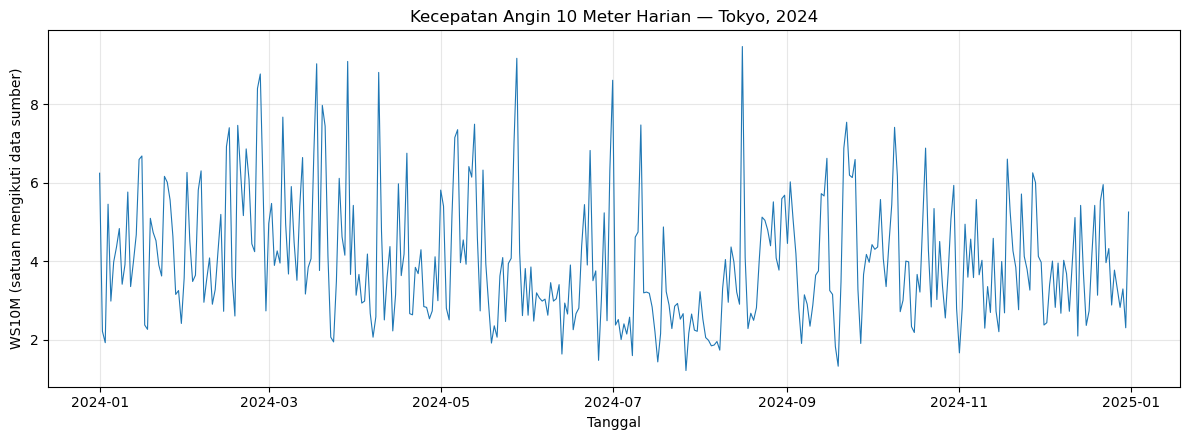

In [13]:
plt.figure(figsize=(12, 4.5))
plt.plot(df["DATE"], df["WS10M"], linewidth=0.8)
plt.title("Kecepatan Angin 10 Meter Harian — Tokyo, 2024")
plt.xlabel("Tanggal")
plt.ylabel("WS10M (satuan mengikuti data sumber)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Visualisasi 2 — Histogram
Histogram menunjukkan bagaimana nilai `WS10M` tersebar dan pada rentang mana pengamatan paling banyak terkumpul.

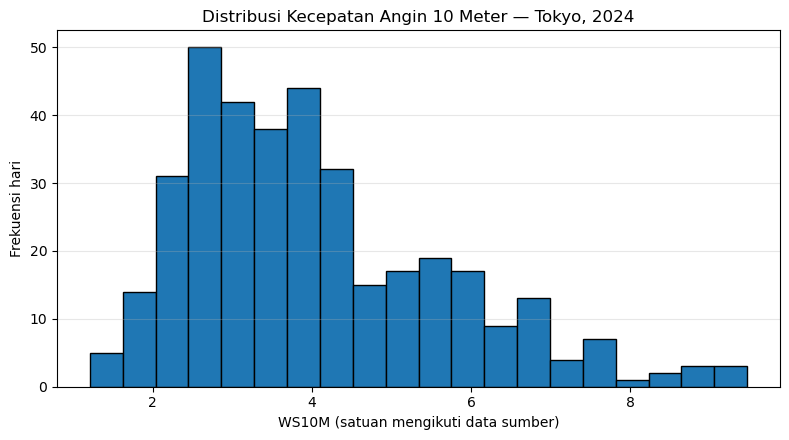

In [14]:
plt.figure(figsize=(8, 4.5))
plt.hist(df["WS10M"].dropna(), bins=20, edgecolor="black")
plt.title("Distribusi Kecepatan Angin 10 Meter — Tokyo, 2024")
plt.xlabel("WS10M (satuan mengikuti data sumber)")
plt.ylabel("Frekuensi hari")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Output dan pemeriksaan akhir
Pemeriksaan akhir memastikan statistik dapat dihitung, hasil numerik tidak kosong, dan kedua recipe telah menghasilkan artifact laporan/catatan.

In [15]:
checks_final = {
    "Statistik WS10M berhasil dihitung": statistik_ws10m.notna().any(),
    "Rata-rata WS10M berupa nilai numerik": np.isfinite(df["WS10M"].mean()),
    "Laporan audit buku berhasil dibuat": Path("station-summary.md").exists(),
    "Catatan recipe mandiri berhasil dibuat": Path("catatan-R-MET-001.md").exists()
}
for nama, hasil in checks_final.items():
    print(("PASS" if hasil else "FAIL") + " — " + nama)
assert all(checks_final.values()), "Ada pemeriksaan akhir yang belum lulus."

PASS — Statistik WS10M berhasil dihitung
PASS — Rata-rata WS10M berupa nilai numerik
PASS — Laporan audit buku berhasil dibuat
PASS — Catatan recipe mandiri berhasil dibuat


## 7. Kesimpulan dan Refleksi

### Kesimpulan
Pada praktik recipe dari buku, prosedur audit digunakan untuk mendeteksi struktur data, nilai kosong, dan timestamp duplikat tanpa mengubah data sumber. Pada recipe mandiri, data NASA POWER Tokyo diperiksa terlebih dahulu, lalu parameter `WS10M` diringkas menggunakan statistik deskriptif dan divisualisasikan dengan grafik deret waktu serta histogram.

### Refleksi
Latihan ini menunjukkan bahwa prompt yang baik perlu menyebutkan input, tujuan, batasan, output, dan kriteria pemeriksaan. Recipe yang terstruktur membuat proses lebih mudah diulang dan hasilnya lebih mudah ditinjau. Analisis yang dilakukan bersifat deskriptif, sehingga tidak digunakan untuk menyimpulkan penyebab meteorologis tanpa analisis tambahan.

### Batasan
1. Data yang dianalisis terbatas pada satu lokasi dan satu tahun.
2. Analisis tidak melakukan pemodelan atau prediksi.
3. Satuan `WS10M` harus dirujuk ke metadata atau dokumentasi sumber NASA POWER yang menyertai data.
4. Data contoh pada bagian R-IO-001 hanya digunakan untuk menguji prosedur audit, bukan sebagai observasi cuaca nyata.